## Overview
This notebook analyzes annual maximum daily maximum temperature (TXx) over the contiguous United States using NClimGrid data for 1952–2025. It fits generalized extreme value (GEV) models using the extRemes workflow, compares stationary and non-stationary assumptions, and visualizes return levels, model parameters, and test results. The maps help show where extreme temperatures and their estimated behavior vary across the region.

## Step 1: Load the data and libraries 
— Read the TXx dataset and import the packages used for analysis and plotting.

In [24]:
import os

In [25]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import scipy
import cftime
import cartopy
import cartopy.crs as ccrs
import matplotlib.colors as mcolors
from copy import copy

In [26]:
from matplotlib import cm
import cmaps
import matplotlib as mpl
from matplotlib.colors import ListedColormap

In [27]:
import warnings
warnings.filterwarnings('ignore')

In [28]:
yearb=1952
yeare=2025
B=300

ifile=f'~/data/TXx/CONUS_TXx_NClimGrid_ij_glostLocSca_extremes_gev_CV_CI300_1952_2025.zarr/'

ds = xr.open_dataset(ifile)
ds = ds.assign_coords(quantile = [0.05,0.5,0.95])
rl = ds['rl']
location = ds['location']
scale = ds['scale']
shape = ds['shape']
pvalueL = ds['pvalueL']
pvalueS = ds['pvalueS']
AIC = ds['AIC']
BIC = ds['BIC']
location_q = ds['location_q']
scale_q = ds['scale_q']
rl_q = ds['rl_q']
Difflocation_q = ds['Difflocation_q']
Diffscale_q = ds['Diffscale_q']
Diffrl_q = ds['Diffrl_q']
CRPS_cv = ds['CRPS_cv']
DawSeb_cv = ds['DawSeb_cv']
SE_cv = ds['SE_cv']
KS_D_cv = ds['KS_D_cv']
KS_pvalue_cv = ds['KS_pvalue_cv']
CVM_D_cv = ds['CVM_D_cv']
CVM_pvalue_cv = ds['CVM_pvalue_cv']
#AIC_cv = ds['AIC_cv']
#BIC_cv = ds['BIC_cv']

Tlon = ds.lon.data
Tlat = ds.lat.data

return_periods = ds.return_periods.data

units = '°F'

## Step 2: Prepare the spatial data 
— Select the analysis period and geographic domain, and organize the data for grid-cell calculations.

In [29]:
# Define state borders feature
state_borders =\
cartopy.feature.NaturalEarthFeature(category='cultural',\
        name='admin_1_states_provinces_lakes', scale='50m', facecolor='none')
# 1. Define the 50m rivers feature
rivers = cartopy.feature.NaturalEarthFeature(
    category='physical',
    name='rivers_lake_centerlines',
    scale='50m',
    facecolor='none',
    edgecolor='blue'  # Or use 'navy', 'royalblue', etc.
)

In [30]:
Tyears=[1979,1960,1970,1980,1990,2000,2010,2020,2025]
Tyears=[1952,2025]
AEP = [1/irp for irp in return_periods]

In [31]:
I_colors = ['green','yellow','red','pink']
cmapI = mcolors.LinearSegmentedColormap.from_list("my_gradient", I_colors)
cmapAr= 'coolwarm_r'
cmapA = 'coolwarm'

In [32]:
latN = 50
latS = 25
lonW = -119.5
lonE = -74

cLat = (latN + latS)/2
cLon = (lonW + lonE )/2

## Step 3: Create maps 
— Plot return levels, parameter estimates, and model-test results across the study area.

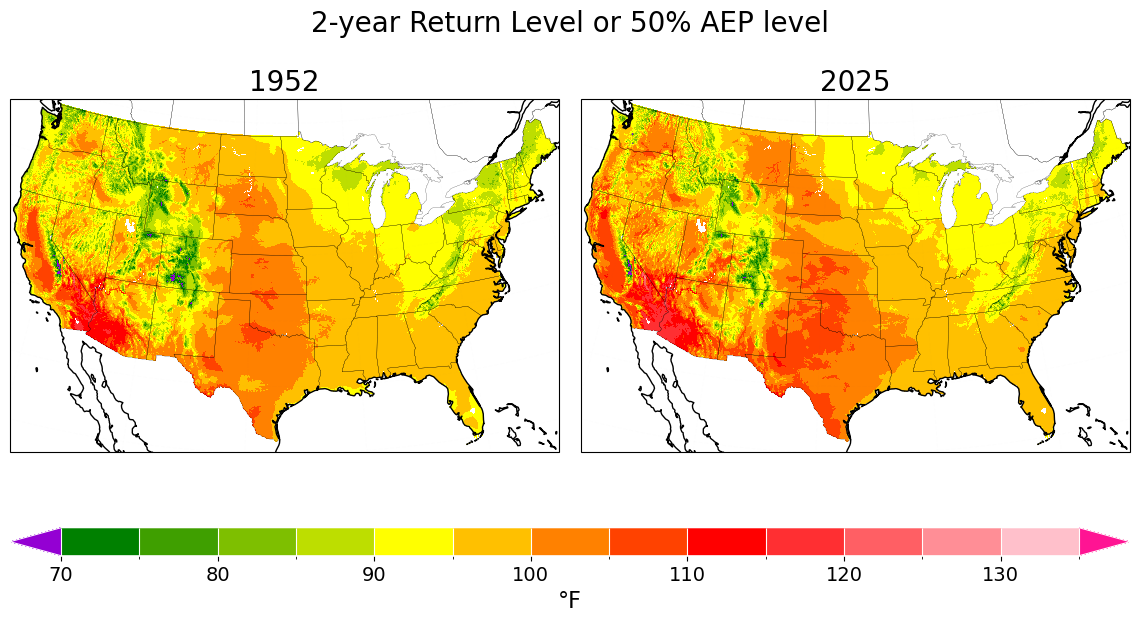

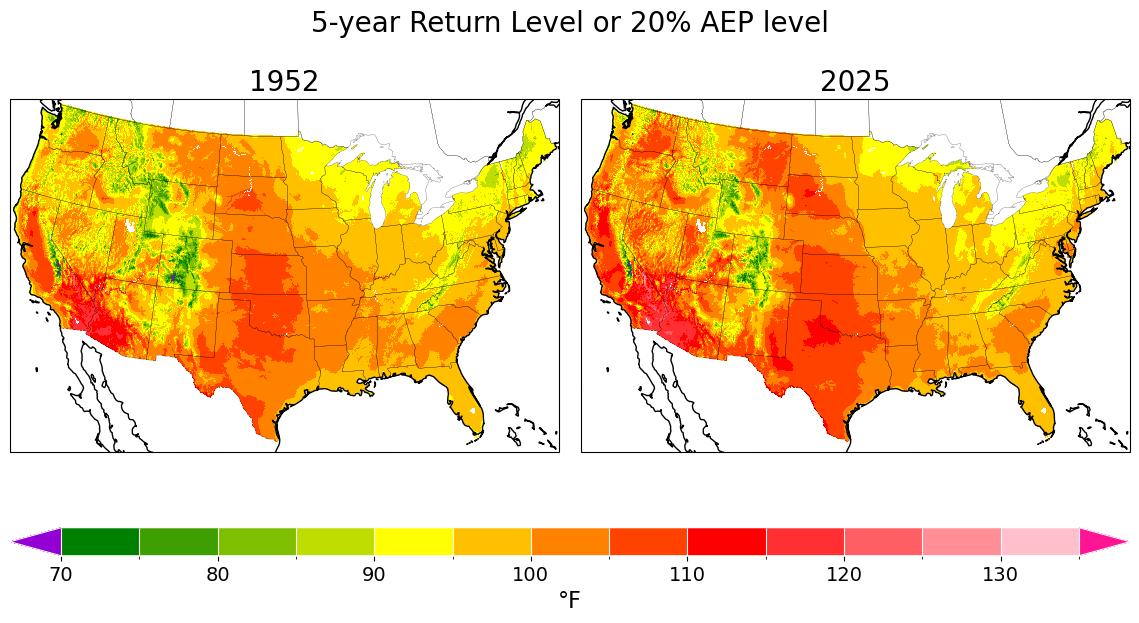

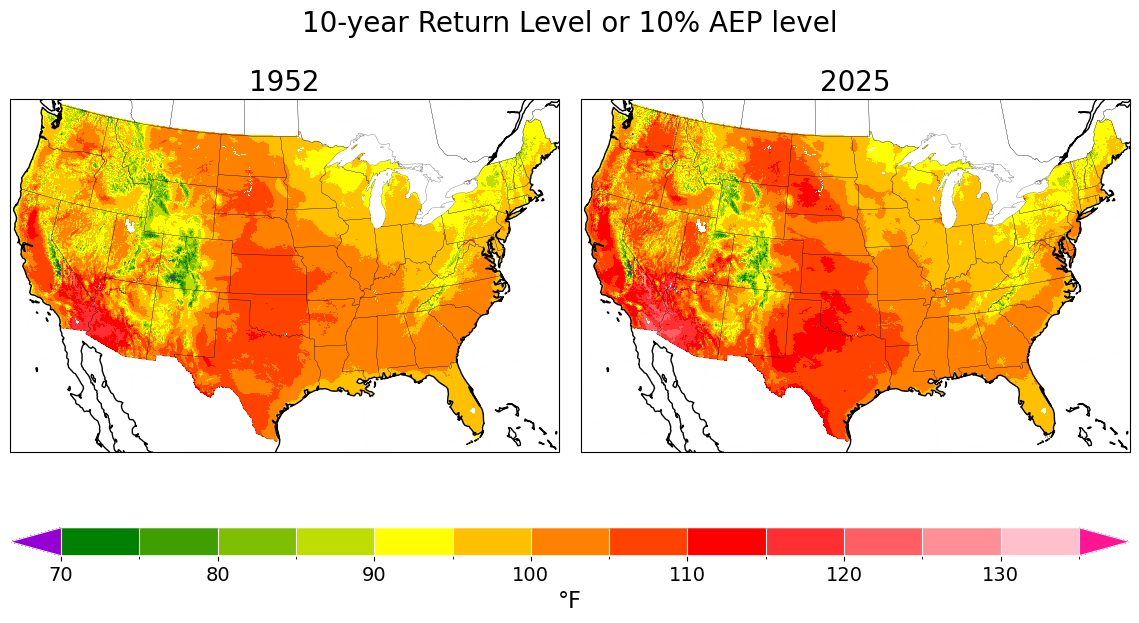

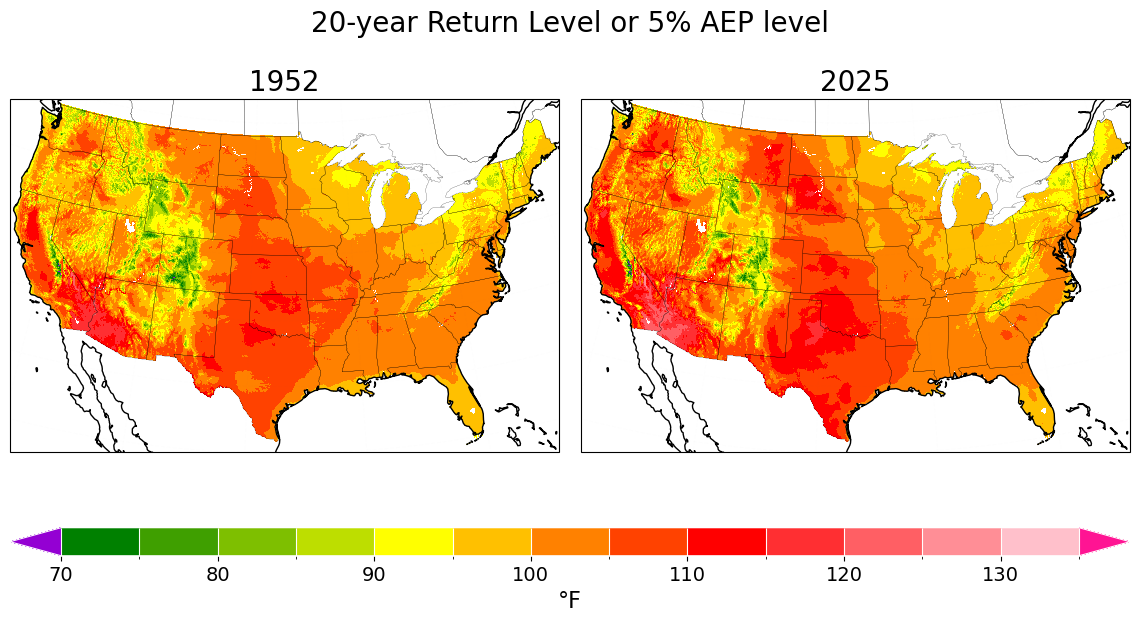

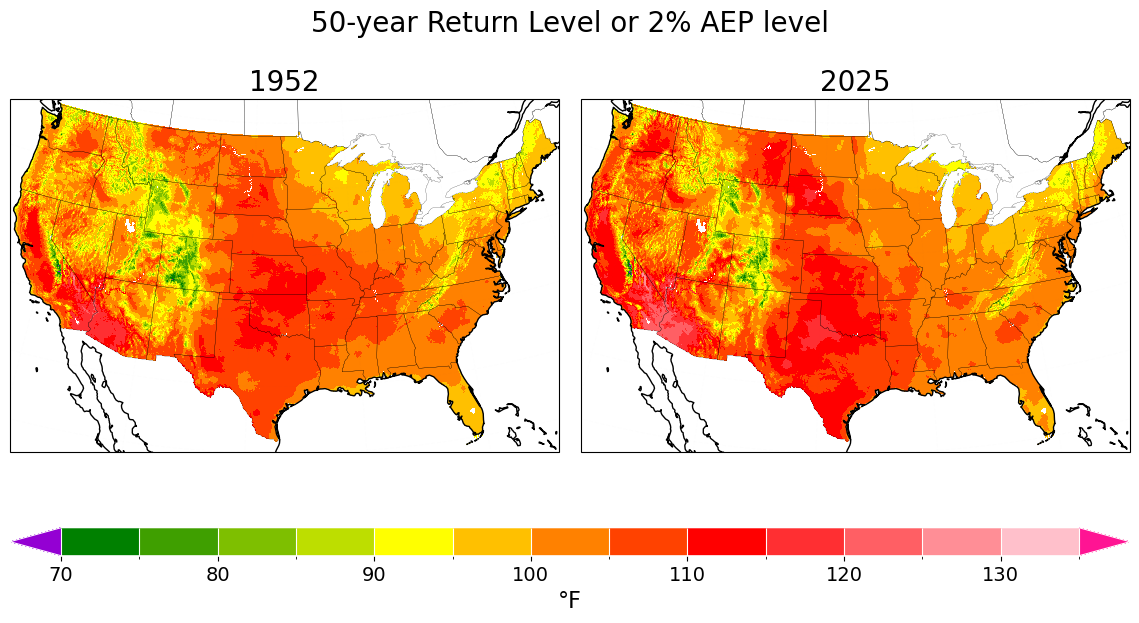

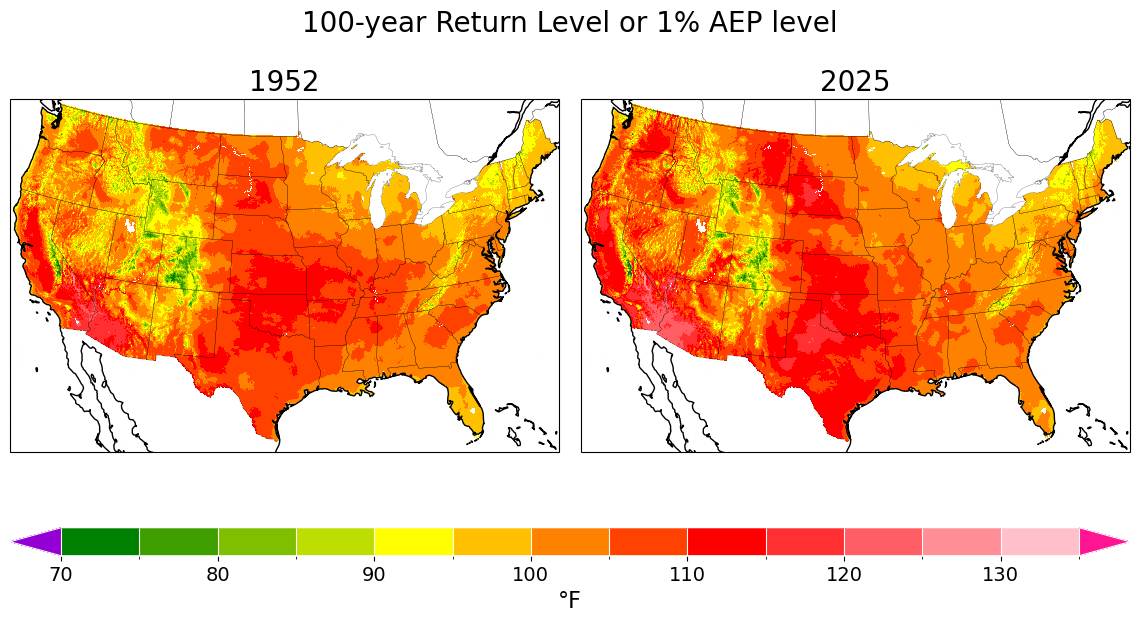

In [33]:

proj=ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

clevs = np.arange(70,140,5)
cmap = plt.get_cmap(cmapI,len(clevs)).copy()
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)

for irp in range(0,len(return_periods)):
  fig, ax = plt.subplots(nrows=1,ncols=2,figsize=(14,7),subplot_kw={'projection':proj})

  plt.subplots_adjust(bottom=0.3,left=0.1, right=0.9,top=0.9,hspace=0.2,wspace=0.04)
  ax = ax.flatten()
  for ix in range(0,len(Tyears)):
    cc = rl.isel(return_periods=irp).sel(time=Tyears[ix]).\
    plot.pcolormesh(ax=ax[ix],cmap=cmap,norm=norm,transform=ccrs.PlateCarree(),add_colorbar=False)
    ax[ix].set_title(f'{Tyears[ix]}',fontsize=20)  
  ##
  for ix in range(0,len(ax)):
    ####
    grd = ax[ix].gridlines(
      draw_labels=False, 
      color='gray', alpha=0.01, linestyle='--')
    grd.top_labels = False   # Disable top labels
    grd.right_labels = False # Disable right labels. 
    ax[ix].set_extent((lonW,lonE,latS,latN), crs=proj_data)
    ax[ix].add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
    ax[ix].coastlines()

  #
  ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])

  cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',drawedges=True,extend='both')
  cbar.ax.tick_params(labelsize=14)  
  cbar.set_label(label=f'{units}',fontsize=16)  
  cbar.outline.set_edgecolor('w')
  cbar.dividers.set_edgecolor('w')
  cbar.dividers.set_linewidth(0.8)
  # create a second axes instance and set the limits you need
  #cax2 = cbar.ax.twiny()
  #cax2.set_xlim(cbar.ax.get_xlim()) 
  #cax2.set_xlabel('degree-days (°F)',fontsize=16)
  # move ticks and label of colorbar to the left
  #c_ticks = cbar.ax.get_xticks()
  #cax2.set_xticks(c_ticks)
  #cax2.set_xticklabels([f'{t*1.8:.0f}' for t in c_ticks],fontsize=14)

  plt.suptitle(f'{return_periods[irp]}-year Return Level or {AEP[irp]*100:.0f}% AEP level',fontsize=20)  

*Return-level maps:
These panels show the estimated return level for selected return periods at two reference years (1952, 2025), illustrating how the intensity of extreme events varies geographically.*


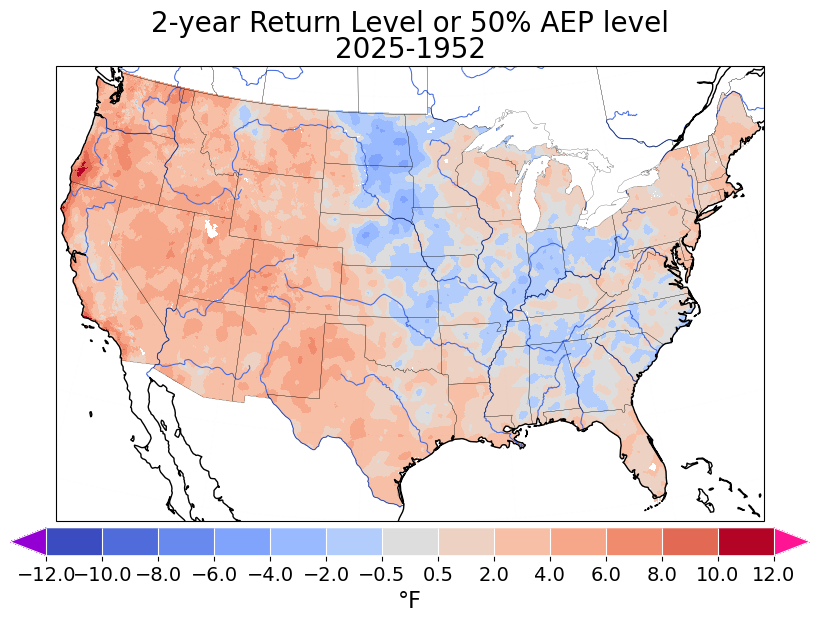

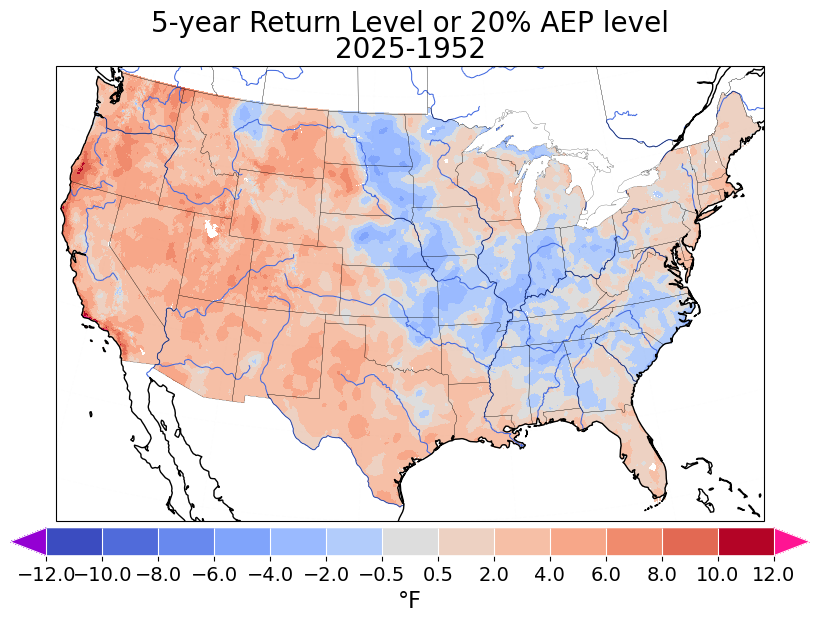

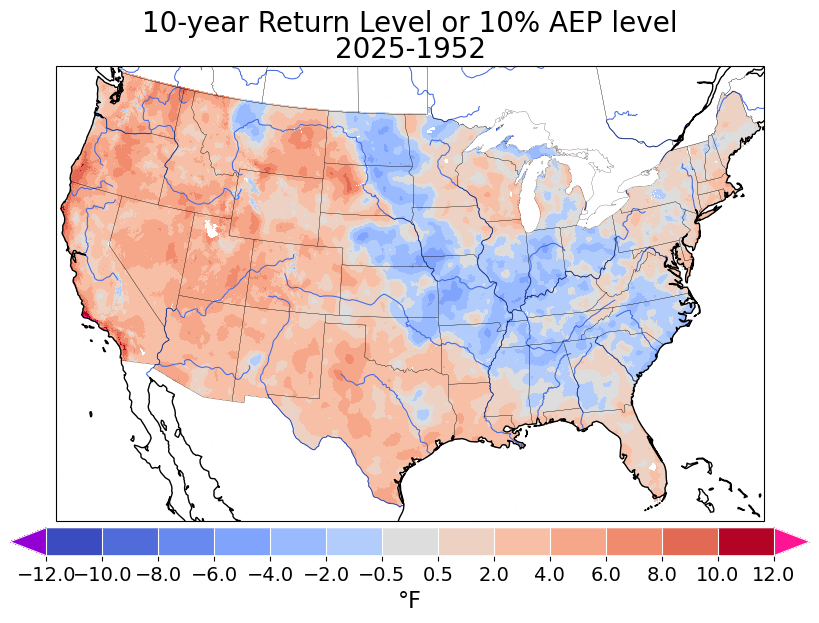

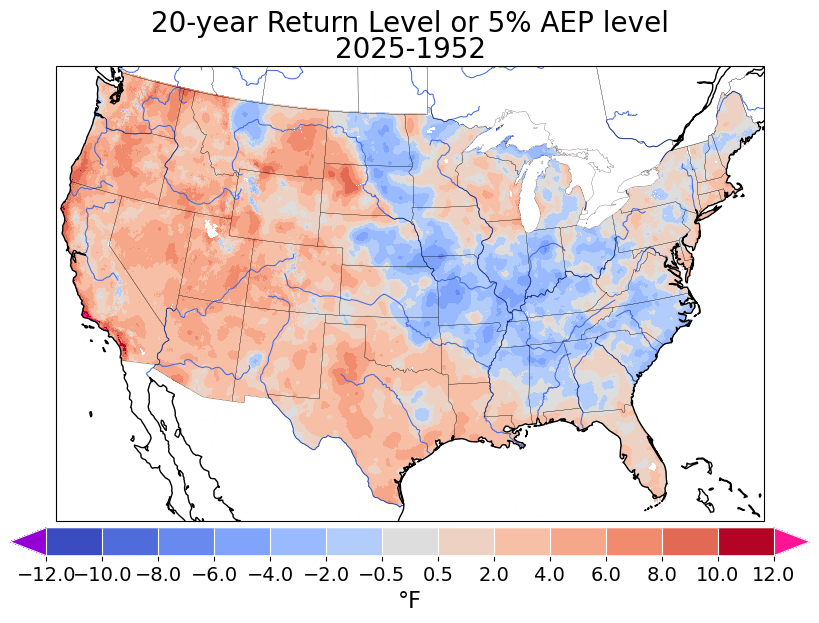

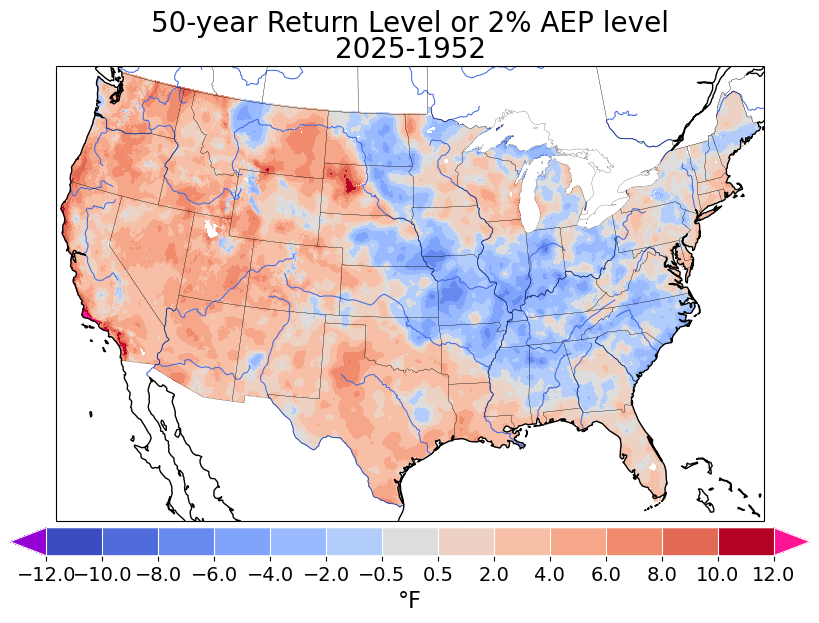

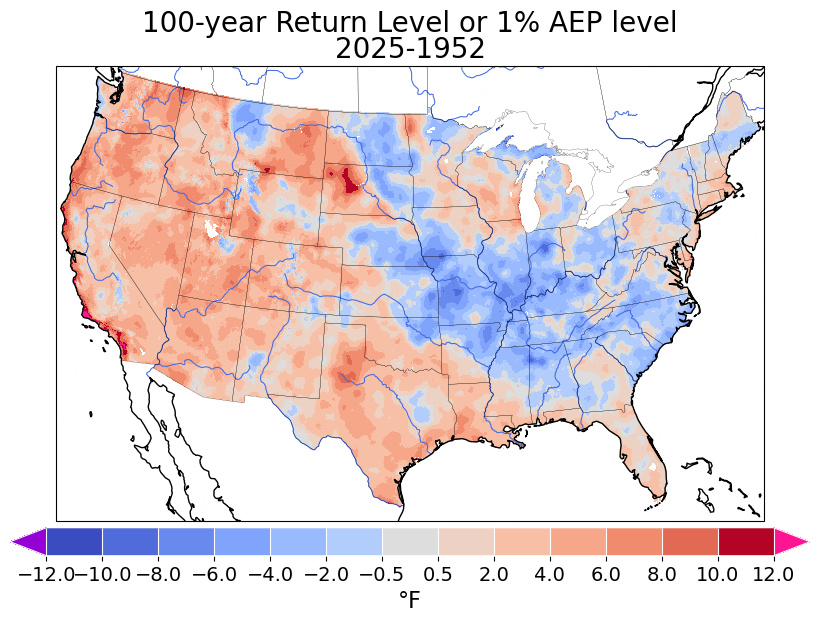

In [34]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

clevst = np.arange(-12,14,2)

clevs= np.concatenate((np.arange(-12,0,2),[-0.5,0.5] ,np.arange(2,14,2)))
cmap = cm.get_cmap(cmapA,len(clevs)+1)
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)

for irp in range(0,len(return_periods)):
  fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(10,7),subplot_kw={'projection':proj})
  plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.9,hspace=0.2,wspace=0.04)

  cc = (rl.isel(return_periods=irp).sel(time=Tyears[-1])-rl.isel(return_periods=irp).sel(time=Tyears[0])).\
    plot.pcolormesh(ax=ax,transform=ccrs.PlateCarree(),cmap=cmap,norm=norm,add_colorbar=False)
  ax.set_title(f'{Tyears[-1]}-{Tyears[0]}',fontsize=20)  
  ##

  ####
  grd = ax.gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
  grd.top_labels = False   # Disable top labels
  grd.right_labels = False # Disable right labels. 
  ax.set_extent((lonW,lonE,latS,latN), crs=proj_data)
  ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
  ax.add_feature(rivers, edgecolor='royalblue', linewidth=0.75)

  ax.coastlines()

  #
  ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])
  cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',extend='both',drawedges=True)
  cbar.set_ticks(clevs[:])
  cbar.ax.tick_params(labelsize=14)  
  cbar.set_label(label=f'{units}',fontsize=16)  
  cbar.outline.set_edgecolor('w')
  cbar.dividers.set_edgecolor('w')
  cbar.dividers.set_linewidth(0.8)

  plt.suptitle(f'{return_periods[irp]}-year Return Level or {AEP[irp]*100:.0f}% AEP level',fontsize=20) 

*Change between two time periods:
These maps show the difference in return level between the end and start of the record, helping to visualize temporal change in the extreme-value field.*


In [35]:

## Build colorbar
from matplotlib import cm
clevsa=np.arange(0.05,1.01,0.01)
clevsb=np.arange(0,0.05,0.001)
clevs_pv=np.concatenate((clevsb,clevsa))
cmap = cm.get_cmap('Purples',len(clevsa)+20)
cmaplist = [cmap(i) for i in range(20,cmap.N)]
cmap2 = cm.get_cmap('YlGn_r', len(clevsb)+5)
cmaplist2 = [cmap2(i) for i in range(0,cmap2.N-5)]

pvalue_cmap = mcolors.LinearSegmentedColormap.from_list('Custom cmap',\
                cmaplist2+cmaplist, len(cmaplist2)+len(cmaplist))

Text(0.5, 0.98, 'p-value Non Stationnary hypothesis')

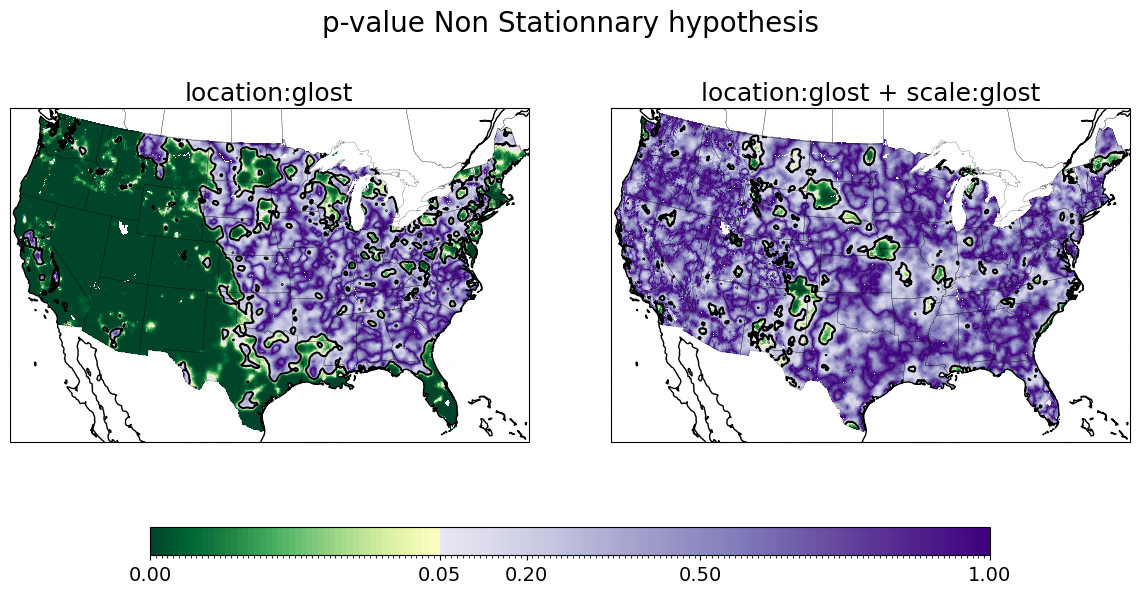

In [36]:
fig, ax = plt.subplots(nrows=1,ncols=2,figsize=(14,7),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.95,hspace=0.04,wspace=0.16)
ax = ax.flatten()
cc = pvalueL.plot.pcolormesh(ax=ax[0],cmap=pvalue_cmap,levels=clevs_pv,transform=ccrs.PlateCarree(),add_colorbar=False)
pvalueL.plot.contour(ax=ax[0],colors='k',levels=[0,0.1],transform=ccrs.PlateCarree(),add_colorbar=False)
ax[0].set_title(f'location:glost',fontsize=18)  
cc = pvalueS.plot.pcolormesh(ax=ax[1],cmap=pvalue_cmap,levels=clevs_pv,transform=ccrs.PlateCarree(),add_colorbar=False)
pvalueS.plot.contour(ax=ax[1],colors='k',levels=[0,0.1],transform=ccrs.PlateCarree(),add_colorbar=False)
ax[1].set_title(f'location:glost + scale:glost',fontsize=18)  

for ix in range(0,len(ax)):
    ####
  grd = ax[ix].gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
  grd.top_labels = False   # Disable top labels
  grd.right_labels = False # Disable right labels. 
  ax[ix].set_extent((lonW,lonE,latS,latN), crs=proj_data)
  ax[ix].add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
  ax[ix].coastlines()

#
ax_cbar = fig.add_axes([0.2, 0.2, 0.6, 0.04])
cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',ticks=[0,0.05,0.2,0.5,1])
cbar.ax.tick_params(labelsize=14)  
cbar.set_label(label='',fontsize=16)
#

plt.suptitle(f'p-value Non Stationnary hypothesis',fontsize=20)  

*P-value maps for non-stationarity tests (location and scale). Green shading identifies regions where the mean p-value is less than 0.05, indicating statistically significant non-stationarity at the 95% confidence level; black contours mark areas significant at the 90% confidence level (p < 0.10). Lower p-values reflect stronger evidence for rejecting the stationary-hypothesis null.*

Text(0.5, 0.98, 'Location parameter')

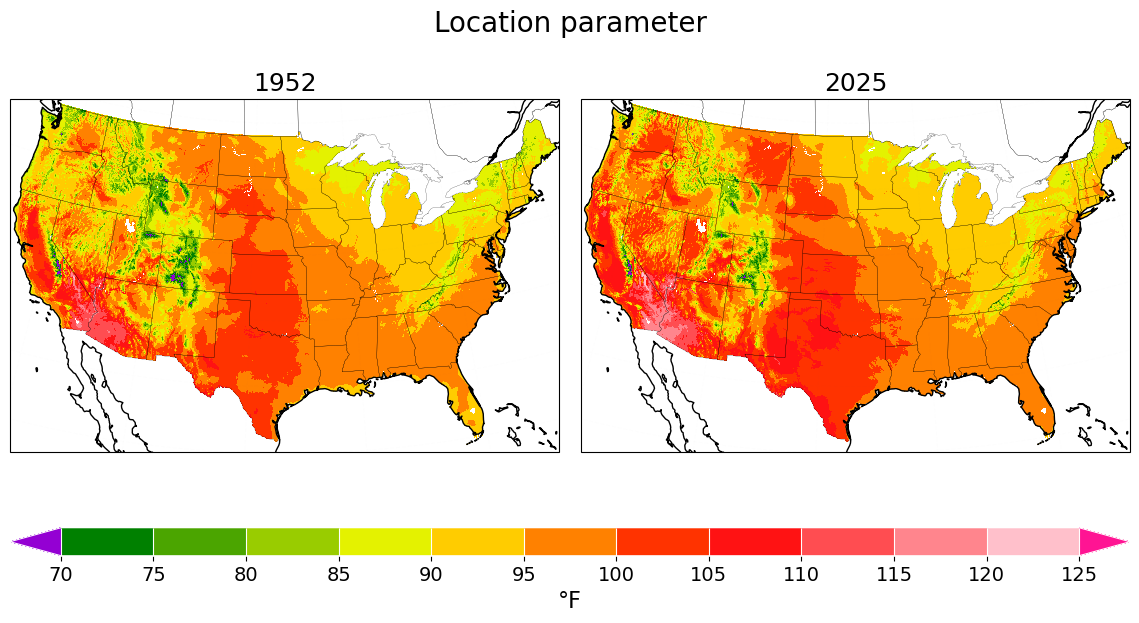

In [37]:
clevs = np.arange(70,130,5)
cmap = plt.get_cmap(cmapI,len(clevs)).copy()
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)

proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

fig, ax = plt.subplots(nrows=1,ncols=2,figsize=(14,7),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.3,left=0.1, right=0.9,top=0.9,hspace=0.2,wspace=0.04)
cc = location.sel(time=yearb).plot.pcolormesh(ax=ax[0],cmap=cmap,norm=norm,transform=ccrs.PlateCarree(),add_colorbar=False)
ax[0].set_title(yearb,fontsize=18)    
location.sel(time=yeare).plot.pcolormesh(ax=ax[1],cmap=cmap,norm=norm,transform=ccrs.PlateCarree(),add_colorbar=False)
ax[1].set_title(yeare,fontsize=18)    

####
for ix in range(0,len(ax)):
    ####
  grd = ax[ix].gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
  grd.top_labels = False   # Disable top labels
  grd.right_labels = False # Disable right labels. 
  ax[ix].set_extent((lonW,lonE,latS,latN), crs=proj_data)
  ax[ix].add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
  ax[ix].coastlines()

#
#
ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])
cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',ticks=clevs[:],drawedges=True,extend='both')
cbar.set_label(label=units,fontsize=16)
cbar.ax.tick_params(labelsize=14)  
cbar.outline.set_edgecolor('w')
cbar.dividers.set_edgecolor('w')
cbar.dividers.set_linewidth(0.8)
plt.suptitle(f'Location parameter',fontsize=20)  

*Spatial distribution of the fitted GEV location parameter for annual maximum daily maximum temperature (TXx) in 1952 (left) and 2025 (right). Colors show the estimated location parameter in °F.*

Text(0.5, 0.98, 'Location parameter')

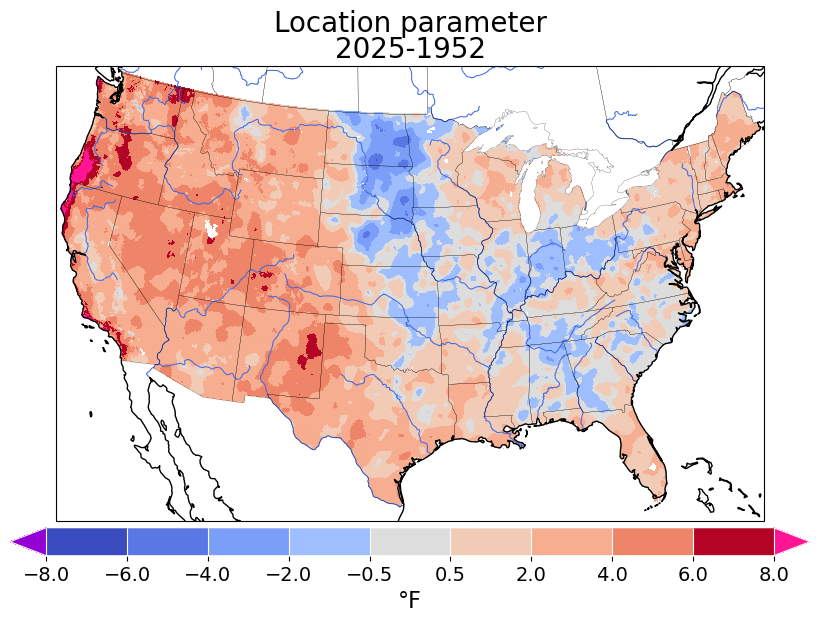

In [38]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

clevst = np.arange(-8,10,2)
clevs= np.concatenate((np.arange(-8,0,2),[-0.5,0.5] ,np.arange(2,10,2)))
cmap = cm.get_cmap(cmapA,len(clevs)+1)
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)

fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(10,7),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.9,hspace=0.2,wspace=0.04)

cc = (location.sel(time=Tyears[-1])-location.sel(time=Tyears[0])).\
  plot.pcolormesh(ax=ax,transform=ccrs.PlateCarree(),cmap=cmap,norm=norm,add_colorbar=False)
ax.set_title(f'{Tyears[-1]}-{Tyears[0]}',fontsize=20)  
##

####
grd = ax.gridlines(
  draw_labels=False, 
  color='gray', alpha=0.01, linestyle='--')
grd.top_labels = False   # Disable top labels
grd.right_labels = False # Disable right labels. 
ax.set_extent((lonW,lonE,latS,latN), crs=proj_data)
ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)  
ax.add_feature(rivers, edgecolor='royalblue', linewidth=0.75)

ax.coastlines()

#
ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])
cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',extend='both',drawedges=True)
cbar.set_ticks(clevs[:])
cbar.ax.tick_params(labelsize=14)  
cbar.set_label(label=f'{units}',fontsize=16)
cbar.outline.set_edgecolor('w')
cbar.dividers.set_edgecolor('w')
cbar.dividers.set_linewidth(0.8)
plt.suptitle(f'Location parameter',fontsize=20)  

*Change in the fitted GEV location parameter for annual maximum daily maximum temperature (TXx) from 1952 to 2025 across the contiguous United States (2025 minus 1952). Positive values indicate an increase; negative values indicate a decrease. Units are degrees Fahrenheit (°F).*

Text(0.5, 0.98, 'Scale parameter')

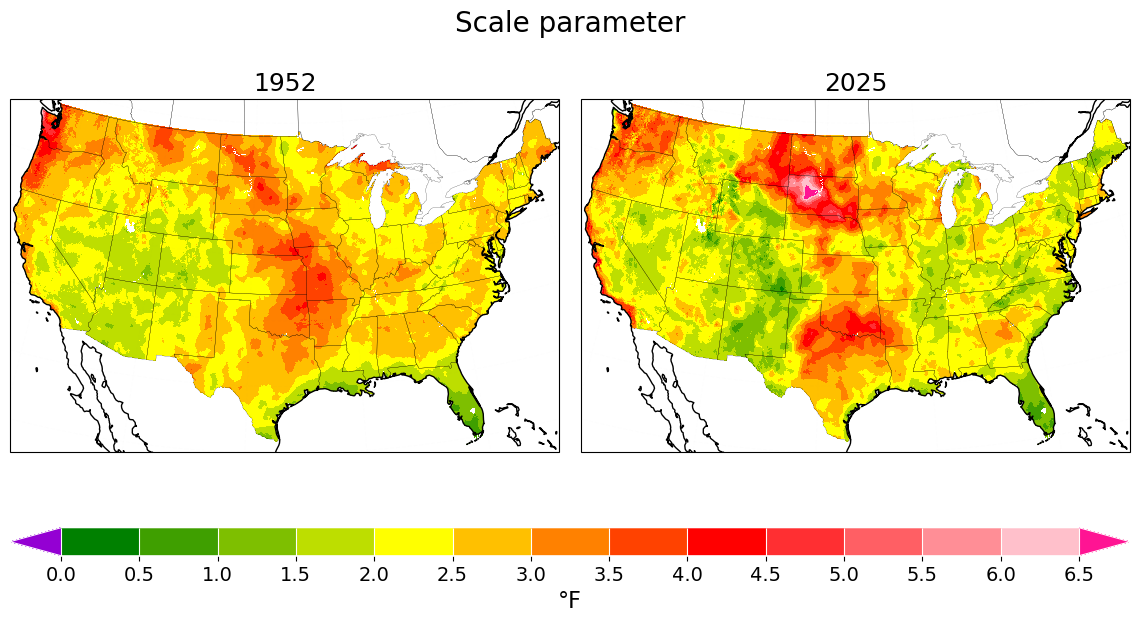

In [39]:

clevs = np.arange(0,7,0.5)
cmap = plt.get_cmap(cmapI,len(clevs)).copy()
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)

proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

fig, ax = plt.subplots(nrows=1,ncols=2,figsize=(14,7),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.3,left=0.1, right=0.9,top=0.9,hspace=0.2,wspace=0.04)
cc = scale.sel(time=yearb).plot.pcolormesh(ax=ax[0],cmap=cmap,norm=norm,transform=ccrs.PlateCarree(),add_colorbar=False)
ax[0].set_title(yearb,fontsize=18)    
scale.sel(time=yeare).plot.pcolormesh(ax=ax[1],cmap=cmap,norm=norm,transform=ccrs.PlateCarree(),add_colorbar=False)
ax[1].set_title(yeare,fontsize=18)    

####
for ix in range(0,len(ax)):
    ####
  grd = ax[ix].gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
  grd.top_labels = False   # Disable top labels
  grd.right_labels = False # Disable right labels. 
  ax[ix].set_extent((lonW,lonE,latS,latN), crs=proj_data)
  ax[ix].add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
  ax[ix].coastlines()

#
#
ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])
cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',ticks=clevs[:],drawedges=True,extend='both')
cbar.set_label(label=units,fontsize=16)
cbar.ax.tick_params(labelsize=14)  
cbar.outline.set_edgecolor('w')
cbar.dividers.set_edgecolor('w')
cbar.dividers.set_linewidth(0.8)
plt.suptitle(f'Scale parameter',fontsize=20)  

*Spatial distribution of the fitted GEV scale parameter for annual maximum daily maximum temperature (TXx) in 1952 (left) and 2025 (center). Scale parameter values are shown in degrees Fahrenheit (°F).*

In [40]:
np.concatenate((np.arange(-0.6,0,0.2),[-0.05,0.05] ,np.arange(0.2,0.7,0.2)))

array([-0.6 , -0.4 , -0.2 , -0.05,  0.05,  0.2 ,  0.4 ,  0.6 ])

Text(0.5, 0.98, 'Shape parameter')

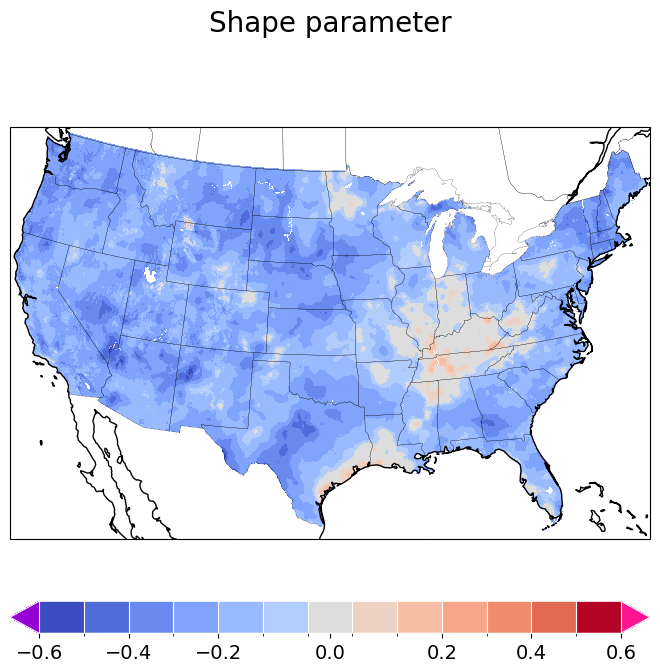

In [41]:
clevst = np.arange(-0.6,0.8,0.1)
clevs= np.concatenate((np.arange(-0.6,0,0.1),[-0.05,0.05] ,np.arange(0.1,0.7,0.1)))
cmap = cm.get_cmap(cmapA,len(clevs)+1)
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)

proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()
fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(8,8),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.9,hspace=0.04,wspace=0.16)
cc = shape.sel(time=yeare).plot.pcolormesh(ax=ax,cmap=cmap,norm=norm,transform=ccrs.PlateCarree(),add_colorbar=False)
ax.set_title('',fontsize=18) 
####

####
grd = ax.gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
grd.top_labels = False   # Disable top labels
grd.right_labels = False # Disable right labels. 
ax.set_extent((lonW,lonE,latS,latN), crs=proj_data)
ax.add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
ax.coastlines()
#
#
ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])
cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',ticks=clevst[::2],drawedges=True,extend='both')
cbar.ax.tick_params(labelsize=14)  
cbar.outline.set_edgecolor('w')
cbar.dividers.set_edgecolor('w')
cbar.dividers.set_linewidth(0.8)
plt.suptitle(f'Shape parameter',fontsize=20)  

*Spatial distribution of the fitted GEV shape parameter for annual maximum daily maximum temperature (TXx). The dimensionless shape parameter is assumed to be constant over time.*

Text(0.5, 0.98, 'Tests averaged in Time')

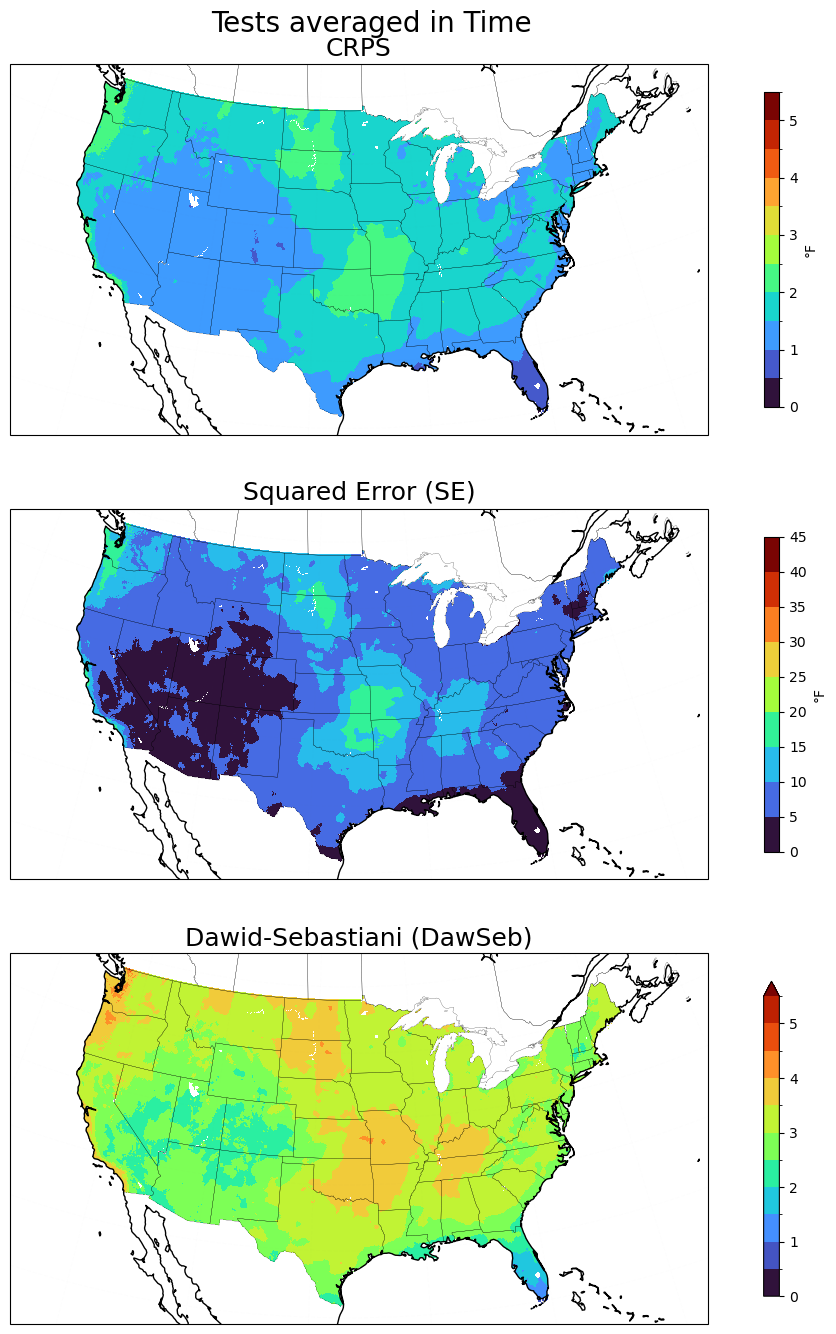

In [42]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

fig, ax = plt.subplots(nrows=3,ncols=1,figsize=(14,18),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.95,hspace=0.2,wspace=0.02)

ax = ax.flatten()
clevs = np.arange(0,6,0.5)
cc = CRPS_cv.mean('time').plot.pcolormesh(ax=ax[0],cmap='turbo',levels=clevs,transform=ccrs.PlateCarree(),cbar_kwargs={'shrink':0.85,'label':units})
ax[0].set_title(f'CRPS',fontsize=18)  
clevs = np.arange(0,50,5)
cc = SE_cv.mean('time').plot.pcolormesh(ax=ax[1],cmap='turbo',levels=clevs,transform=ccrs.PlateCarree(),cbar_kwargs={'shrink':0.85,'label':units})
ax[1].set_title(f'Squared Error (SE)',fontsize=18)  
clevs = np.arange(0,6,0.5)
cc = DawSeb_cv.mean('time').plot.pcolormesh(ax=ax[2],cmap='turbo',levels=clevs,transform=ccrs.PlateCarree(),cbar_kwargs={'shrink':0.85,'label':''})
ax[2].set_title(f'Dawid-Sebastiani (DawSeb)',fontsize=18)  

for ix in range(0,len(ax)):
    ####
  grd = ax[ix].gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
  grd.top_labels = False   # Disable top labels
  grd.right_labels = False # Disable right labels. 
  ax[ix].add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
  ax[ix].coastlines()

#

plt.suptitle(f'Tests averaged in Time',fontsize=20)  

*Diagnostics (CRPS / SE / Dawid–Sebastiani): Time-averaged diagnostic maps that assess predictive performance; see Technical details for scoring definitions.*

Text(0.5, 0.98, 'Tests averaged in Time')

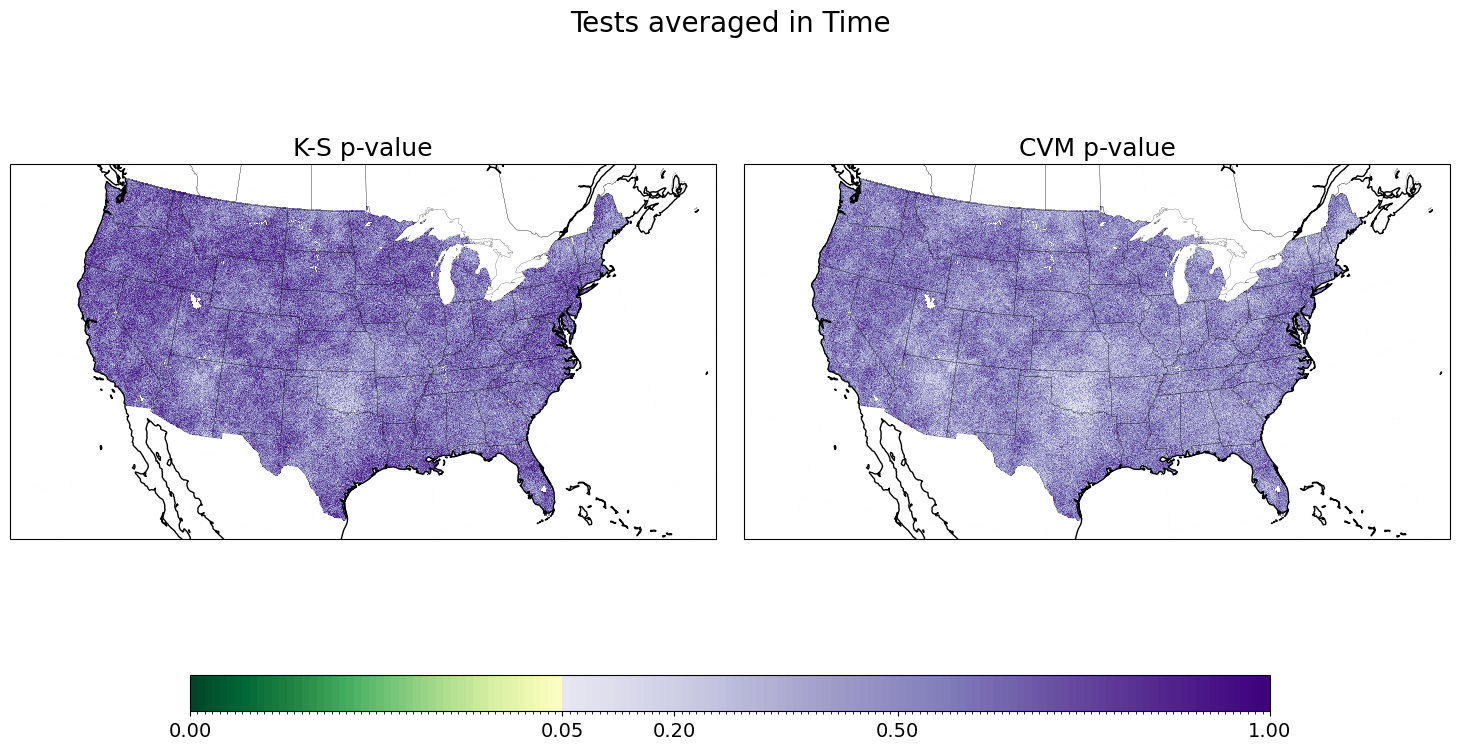

In [43]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

fig, ax = plt.subplots(nrows=1,ncols=2,figsize=(18,9),subplot_kw={'projection':proj})
plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.95,hspace=0.04,wspace=0.04)
ax = ax.flatten()
cc = KS_pvalue_cv.mean('time').plot.pcolormesh(ax=ax[0],cmap=pvalue_cmap,levels=clevs_pv,transform=ccrs.PlateCarree(),add_colorbar=False)
ax[0].set_title(f'K-S p-value',fontsize=18)  
cc = CVM_pvalue_cv.mean('time').plot.pcolormesh(ax=ax[1],cmap=pvalue_cmap,levels=clevs_pv,transform=ccrs.PlateCarree(),add_colorbar=False)
ax[1].set_title(f'CVM p-value',fontsize=18)  

for ix in range(0,len(ax)):
    ####
  grd = ax[ix].gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
  grd.top_labels = False   # Disable top labels
  grd.right_labels = False # Disable right labels. 
  ax[ix].add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
  ax[ix].coastlines()

ax_cbar = fig.add_axes([0.2, 0.2, 0.6, 0.04])
cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',ticks=[0,0.05,0.2,0.5,1])
cbar.ax.tick_params(labelsize=14)   
#
plt.suptitle(f'Tests averaged in Time',fontsize=20)  

*Time-averaged p-value maps from the Kolmogorov–Smirnov (K–S) and Cramér–von Mises (CvM) goodness-of-fit tests. Regions shaded in green indicate p-values < 0.05, corresponding to rejection of the null hypothesis at the 95% significance level and suggesting inadequate model fit. Regions shaded in purple indicate p-values > 0.05, indicating no significant evidence against the fitted distribution. The color scale represents the magnitude of the p-values, with lower values reflecting stronger departures from the assumed model.*

In [44]:
Tquantile=['0.95','0.05']
vq=[float(x) for x in Tquantile]

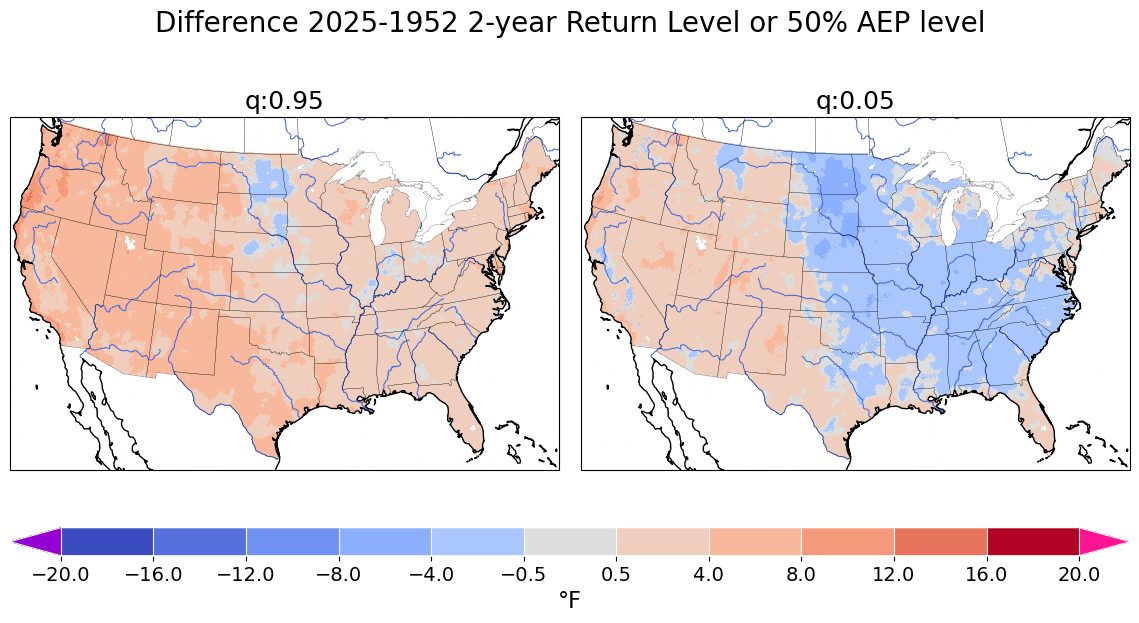

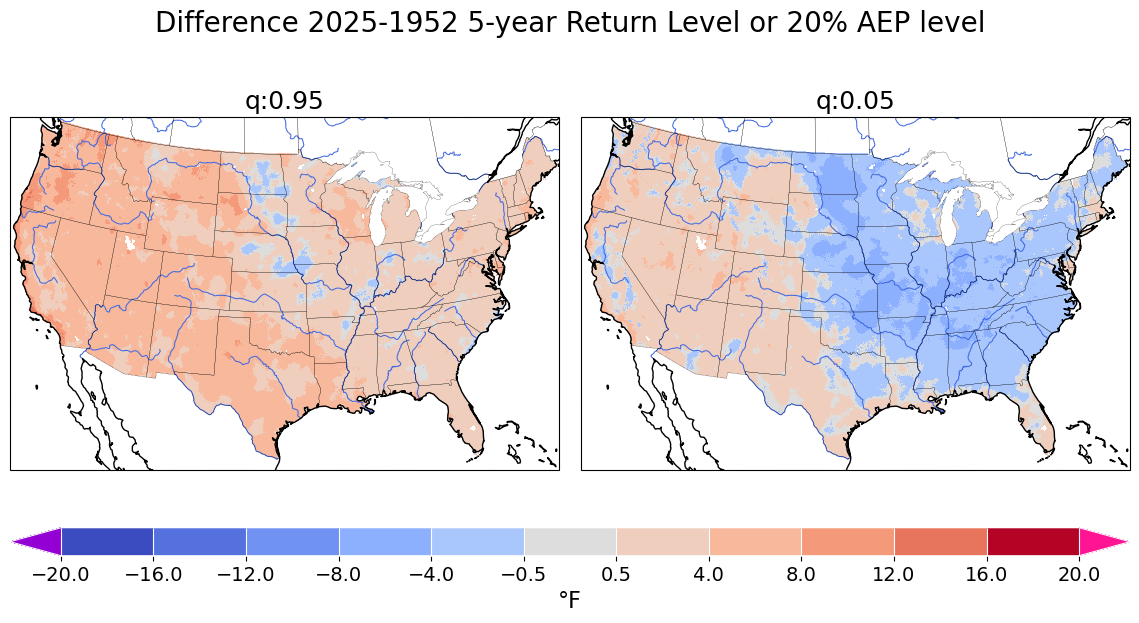

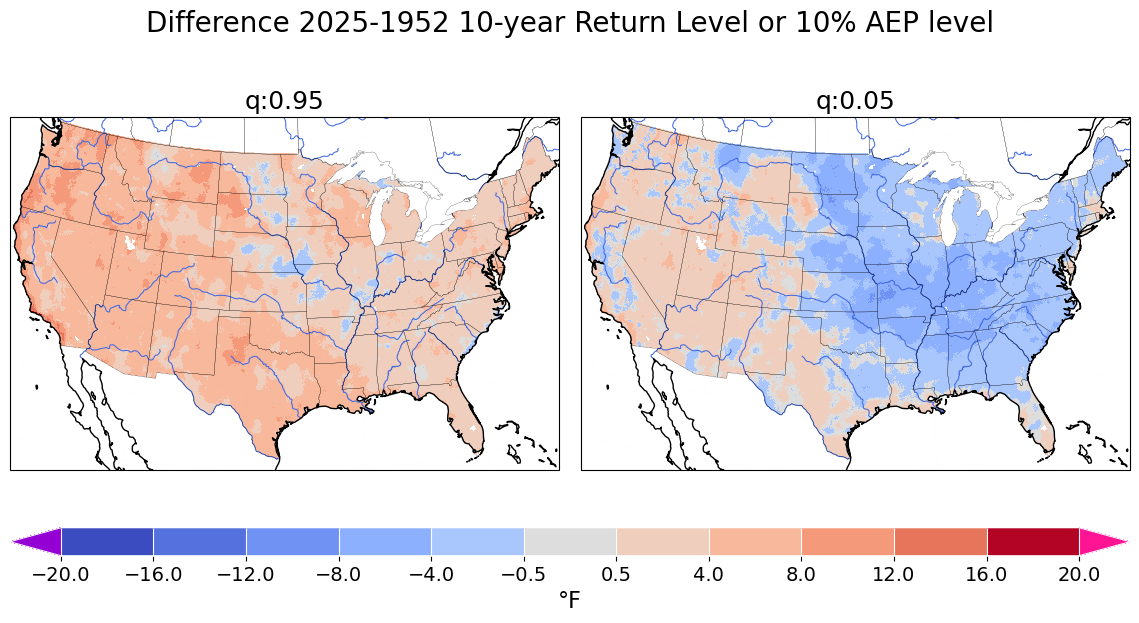

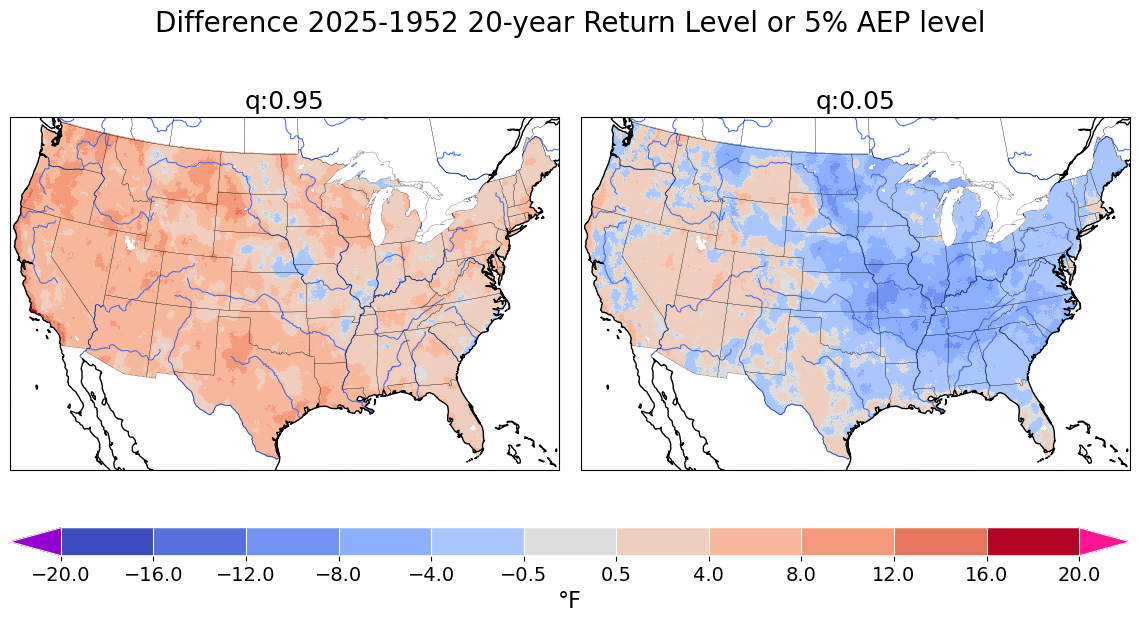

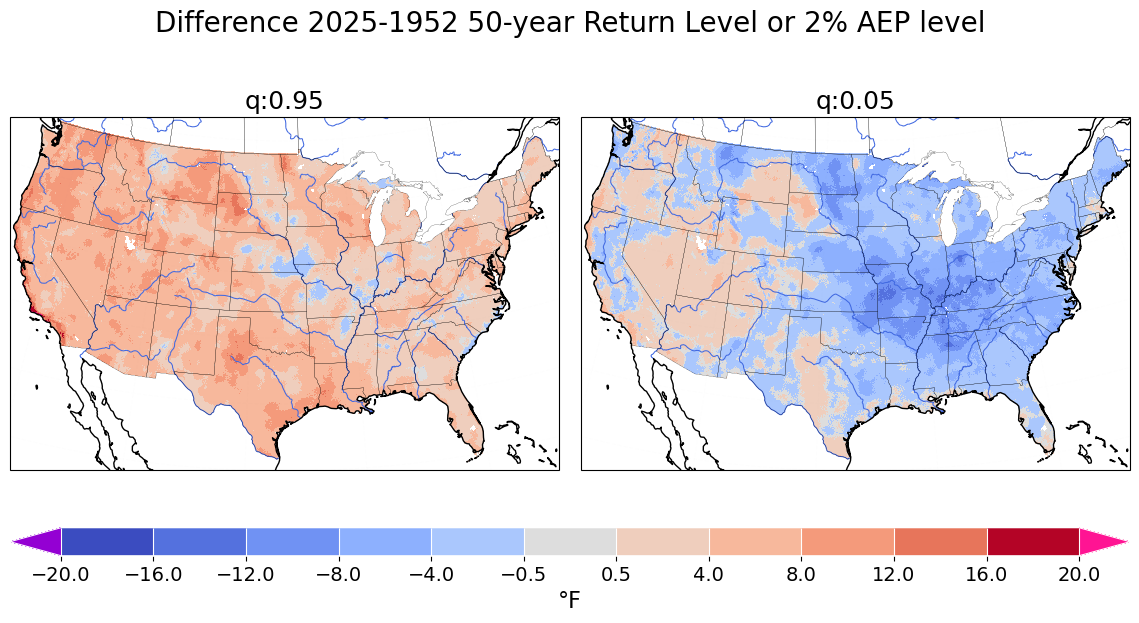

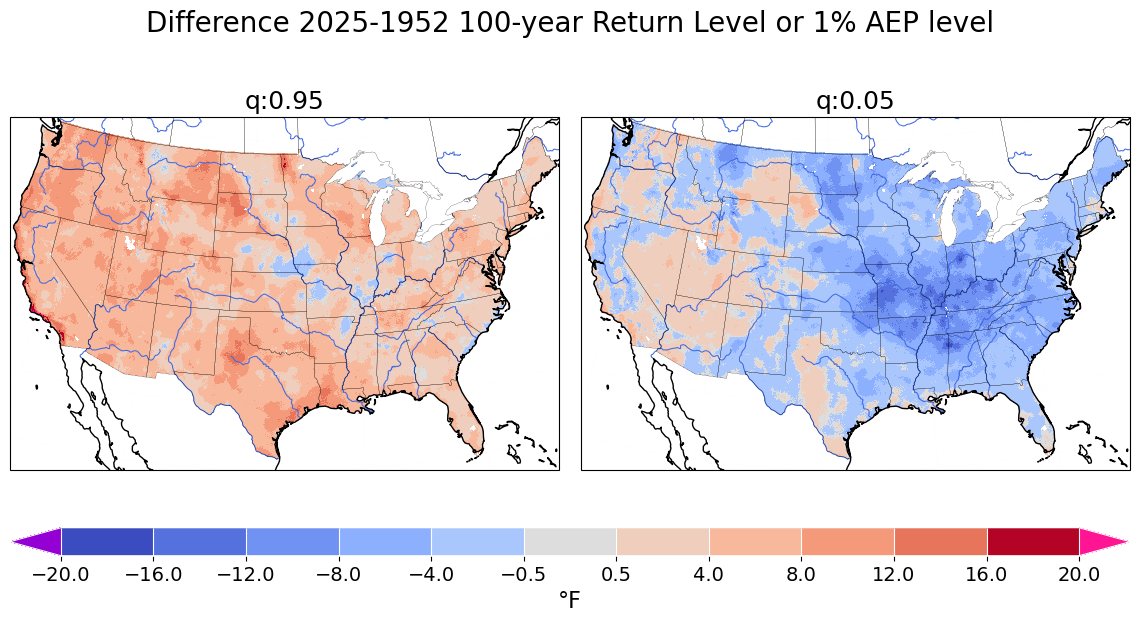

In [46]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

clevst = np.arange(-20,24,4)

clevs= np.concatenate((np.arange(-20,0,4),[-0.5,0.5] ,np.arange(4,24,4)))
cmap = cm.get_cmap(cmapA,len(clevs)+1)
cmap.set_under('darkviolet')
cmap.set_over('deeppink')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap.N)

for irp in range(0,len(return_periods)):
  fig, ax = plt.subplots(nrows=1,ncols=len(Tquantile),figsize=(14,7),subplot_kw={'projection':proj})
  plt.subplots_adjust(bottom=0.25,left=0.1, right=0.9,top=0.9,hspace=0.2,wspace=0.04)

  for ix in range(0,len(Tquantile)):
    cc = Diffrl_q.sel(quantile=vq[ix]).isel(return_periods=irp).plot.pcolormesh\
    (ax=ax[ix],transform=ccrs.PlateCarree(),cmap=cmap,norm=norm,add_colorbar=False)
    ax[ix].set_title(f'q:{Tquantile[ix]}',fontsize=18)   
    ##

    ####
    grd = ax[ix].gridlines(
    draw_labels=False, 
    color='gray', alpha=0.01, linestyle='--')
    grd.top_labels = False   # Disable top labels
    grd.right_labels = False # Disable right labels. 
    ax[ix].set_extent((lonW,lonE,latS,latN), crs=proj_data)
    ax[ix].add_feature(state_borders,zorder=100,edgecolor='k',linewidth=0.15)
    ax[ix].add_feature(rivers, edgecolor='royalblue', linewidth=0.75)
    ax[ix].coastlines()

  #
  ax_cbar = fig.add_axes([0.1, 0.2, 0.8, 0.04])
  cbar=fig.colorbar(cc,cax=ax_cbar,shrink=0.5,orientation='horizontal',extend='both', drawedges=True)
  cbar.set_ticks(clevs[:])
  cbar.ax.tick_params(labelsize=14)  
  cbar.set_label(label=f'{units}',fontsize=16)
  cbar.outline.set_edgecolor('w')
  cbar.dividers.set_edgecolor('w')
  cbar.dividers.set_linewidth(0.8)

  plt.suptitle(f'Difference {yeare}-{yearb} {return_periods[irp]}-year Return Level or {AEP[irp]*100:.0f}% AEP level',fontsize=20)  

*Spatial patterns of change in the lower (q=0.05) and upper (q=0.95) quantiles between the start (1952) and end (2025) period.*

## Step 4: Technical notes

### Scoring formulas

- CRPS for predictive CDF $F$ and observation $y$:

  $$\mathrm{CRPS}(F,y)=\int_{-\infty}^{\infty}(F(x)-\mathbf{1}_{\{x\ge y\}})^2\,dx.$$

- Squared Error (SE):

  $$\mathrm{SE}=(y-\mu)^2.$$

- Dawid–Sebastiani Score (DSS):

  $$\mathrm{DSS}=\frac{(y-\mu)^2}{\sigma^2}+2\log\sigma.$$
